In [2]:
pip install matplotlib

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ------------ --------------------------- 0.8/2.5 MB 3.4 MB/s eta 0:00:01
   ------------------------- -------------- 1.6/2.5 MB 3.5 MB/s eta 0:00:01
   -----------------------------

In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt

In [4]:
import os
print("current directory:", os.getcwd())

current directory: c:\Users\91973\OneDrive\Documents\Desktop\AICW\plant\archive


In [5]:
current_directory = os.getcwd()
train_path=os.path.join(current_directory, "data","Training")
valid_path=os.path.join(current_directory, "data","Validation")
test_path=os.path.join(current_directory, "data","Testing")

In [6]:
train_path

'c:\\Users\\91973\\OneDrive\\Documents\\Desktop\\AICW\\plant\\archive\\data\\Training'

In [7]:
valid_path

'c:\\Users\\91973\\OneDrive\\Documents\\Desktop\\AICW\\plant\\archive\\data\\Validation'

In [8]:
test_path

'c:\\Users\\91973\\OneDrive\\Documents\\Desktop\\AICW\\plant\\archive\\data\\Testing'

In [10]:
training_set=tf.keras.utils.image_dataset_from_directory(
    train_path,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128,128),
    shuffle=True,
    interpolation="bilinear",
)

Found 3251 files belonging to 3 classes.


In [11]:
validation_set=tf.keras.utils.image_dataset_from_directory(
    train_path,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128,128),
    shuffle=True,
    interpolation="bilinear",
)

Found 3251 files belonging to 3 classes.


In [12]:
cnn = tf.keras.models.Sequential()

cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Dropout(0.25))

cnn.add(tf.keras.layers.Flatten())
cnn.add(tf.keras.layers.Dense(units=1500,activation='relu'))
cnn.add(tf.keras.layers.Dropout(0.4))

cnn.add(tf.keras.layers.Dense(units=3,activation='softmax'))

c:\Users\91973\OneDrive\Documents\Desktop\AICW\plant\archive\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [17]:
cnn.compile(optimizer=tf.keras.optimizers.Adam(
    learning_rate=0.0001),loss='categorical_crossentropy',metrics=['accuracy'])

In [16]:
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 126, 126, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 63, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 30, 30, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1500)           │     3,073,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         4,503 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,790,227 (29.72 MB)

 Trainable params: 7,790,227 (29.72 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
training_history= cnn.fit(x=training_set,validation_data=validation_set,epochs=10)

Epoch 1/10


c:\Users\91973\OneDrive\Documents\Desktop\AICW\plant\archive\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


102/102 ━━━━━━━━━━━━━━━━━━━━ 182s 2s/step - accuracy: 0.5275 - loss: 0.9630 - val_accuracy: 0.6749 - val_loss: 0.7943
Epoch 2/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 143s 1s/step - accuracy: 0.7158 - loss: 0.6832 - val_accuracy: 0.8567 - val_loss: 0.4341
Epoch 3/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 151s 1s/step - accuracy: 0.8167 - loss: 0.4644 - val_accuracy: 0.8883 - val_loss: 0.3171
Epoch 4/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step - accuracy: 0.8850 - loss: 0.3297 - val_accuracy: 0.9348 - val_loss: 0.1943
Epoch 5/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 179s 2s/step - accuracy: 0.9043 - loss: 0.2695 - val_accuracy: 0.9489 - val_loss: 0.1643
Epoch 6/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - accuracy: 0.9323 - loss: 0.1859 - val_accuracy: 0.9563 - val_loss: 0.1480
Epoch 7/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 140s 1s/step - accuracy: 0.9422 - loss: 0.1734 - val_accuracy: 0.9597 - val_loss: 0.1321
Epoch 8/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 142s 1s/step - accuracy: 0.9409 - loss: 0.1709 - val_accuracy: 0.980

In [20]:
train_loss, train_acc= cnn.evaluate(validation_set)
print("validation accuracy:",train_acc)

102/102 ━━━━━━━━━━━━━━━━━━━━ 35s 345ms/step - accuracy: 0.9806 - loss: 0.0618
validation accuracy: 0.980621337890625


In [22]:
cnn.save('trained_plant_disease_model.keras')

In [23]:
training_history.history

{'accuracy': [0.5275300145149231,
  0.7157797813415527,
  0.8166717886924744,
  0.8849584460258484,
  0.9043371081352234,
  0.9323285222053528,
  0.9421716332435608,
  0.9409412741661072,
  0.96124267578125,
  0.9640110731124878],
 'loss': [0.9630319476127625,
  0.6832126975059509,
  0.4644424319267273,
  0.3297337591648102,
  0.26951509714126587,
  0.18592824041843414,
  0.17339733242988586,
  0.17090138792991638,
  0.12110591679811478,
  0.09927079826593399],
 'val_accuracy': [0.6748692989349365,
  0.856659471988678,
  0.888342022895813,
  0.9347892999649048,
  0.94893878698349,
  0.956321120262146,
  0.9597046971321106,
  0.980621337890625,
  0.9590895175933838,
  0.980621337890625],
 'val_loss': [0.7943034768104553,
  0.434059739112854,
  0.31712377071380615,
  0.19428467750549316,
  0.16430695354938507,
  0.14800560474395752,
  0.13214552402496338,
  0.0620206743478775,
  0.10839222371578217,
  0.06175948306918144]}

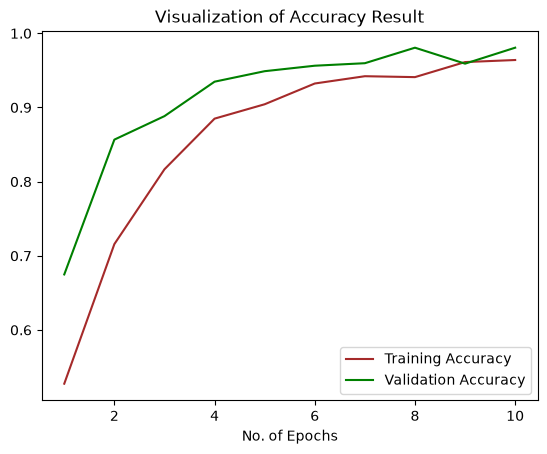

In [25]:
epochs = [i for i in range(1,11)]
plt.plot(epochs,training_history.history['accuracy'],color='brown',label='Training Accuracy')
plt.plot(epochs,training_history.history['val_accuracy'],color='green',label='Validation Accuracy')
plt.xlabel('No. of Epochs')
plt.title('Visualization of Accuracy Result')
plt.legend()
plt.show()